# Лабораторная работа №1. Иерархический кластерный анализ
**Студент:** Диарра Тьекура

**Тема:** Сегментация потребителей леденцов

**Файл данных:** Леденцы.dat

### Цель работы
Разделить потребителей на группы (кластеры) на основе их мотивов покупки леденцов.
Определить оптимальное число кластеров и объяснить, что означает каждая группа (интерпретация).

### Описание данных
В датасете 338 респондентов. Они отвечали на 11 вопросов (V1-V11) о том, зачем они едят леденцы.
Оценки от 1 до 5 (где 5 - полное согласие).

Мы можем разделить вопросы на группы:
- **V1-V4:** Свежесть дыхания и гигиена.
- **V5-V6:** Любовь к сладкому.
- **V7-V8:** Концентрация и отдых.
- **V9-V11:** Лечение (горло, нос, самочувствие).

Наша задача - понять, какие люди объединяются в эти группы.

In [37]:
# 1. Импортируем библиотеки для работы с данными
import pandas as pd
import numpy as np

# 2. Импортируем библиотеки для графиков
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 3. Импортируем инструменты для кластеризации
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

# Настройки для красивых графиков
sns.set_style("whitegrid")

**Объяснение:** Мы загрузили все нужные инструменты. `pandas` - для таблиц, `scipy` - для кластеризации.

In [44]:
# 4. Загружаем данные (разделитель - точка с запятой)
df = pd.read_csv("леденцы.dat", sep=";")

# 5. Смотрим размер таблицы (строки и столбцы)
print("Размер таблицы:", df.shape)

# 6. Смотрим первые 5 строк
display(df.head())

# 7. Проверяем пропущенные значения (0 = нет пропусков)
print("\nПропущенные значения:")
print(df.isnull().sum().sum())

# 8. Смотрим статистику (среднее, мин, макс)
display(df.describe().round(2))

Размер таблицы: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3



Пропущенные значения:
0


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00
mean,3.54,3.53,3.52,3.41,3.21,3.20,3.25,3.29,3.60,3.55,3.57
std,0.96,0.96,0.99,0.99,0.87,0.87,0.84,0.82,0.97,0.93,0.94
min,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00
25%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
50%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
75%,5.00,5.00,5.00,4.00,3.00,3.00,3.00,3.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


**Объяснение:**
Мы загрузили данные. Видим, что в таблице 338 строк и 11 столбцов.
Пропущенных значений нет (сумма = 0). Оценки от 2 до 5.
Средние значения находятся в диапазоне от 3.2 до 3.6. Это значит, что все оценки на одной шкале.
Поэтому **стандартизация (нормализация) не нужна**.


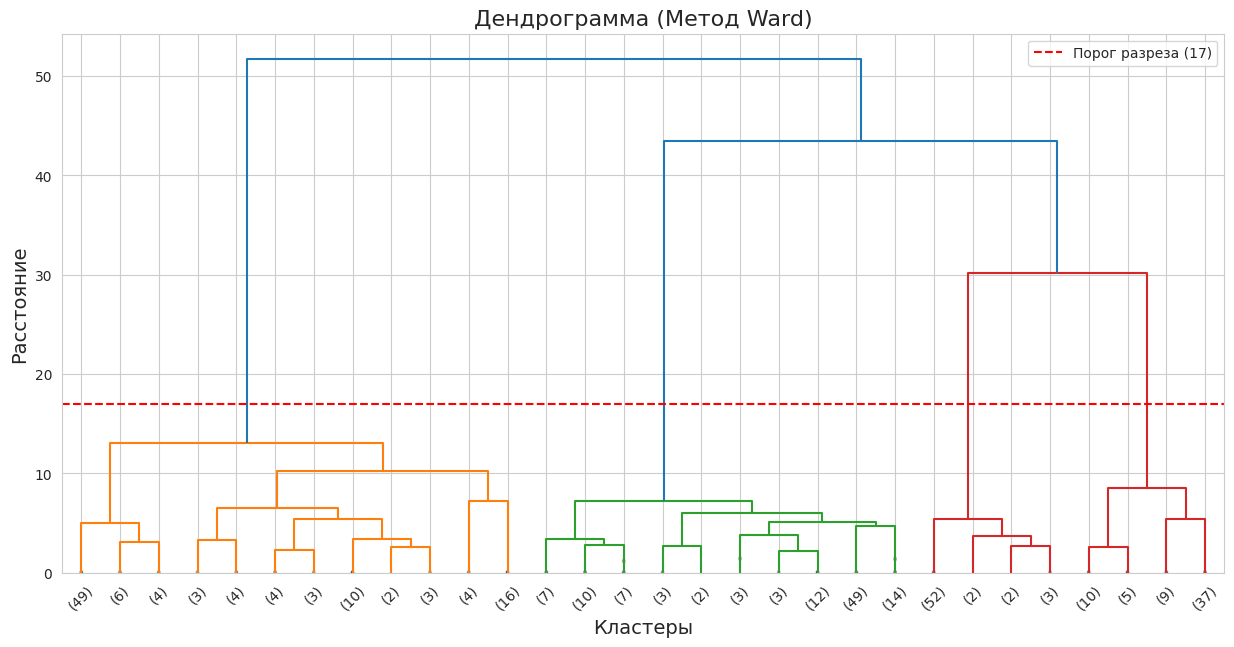

In [45]:
# 9. Создаем матрицу связей (Linkage) методом Ward
# Ward минимизирует дисперсию внутри кластеров, это дает четкие группы
Z = sch.linkage(df, method='ward', metric='euclidean')

# 10. Строим дендрограмму (дерево)
plt.figure(figsize=(15, 7))
# truncate_mode='lastp' и p=30 - чтобы дерево было читаемым (показываем последние 30 групп)
sch.dendrogram(Z, truncate_mode='lastp', p=30, show_contracted=True)
plt.title('Дендрограмма (Метод Ward)', fontsize=16)
plt.xlabel('Кластеры', fontsize=14)
plt.ylabel('Расстояние', fontsize=14)
plt.axhline(y=17, color='red', linestyle='--', label='Порог разреза (17)') # Линия разреза
plt.legend()
plt.show()

**Объяснение:**
Мы построили дерево (дендрограмму).
Красная линия на уровне 17 показывает, где мы режем дерево.
Видно, что линия пересекает 4 большие ветви.
Это значит, что оптимальное число кластеров - **4**.

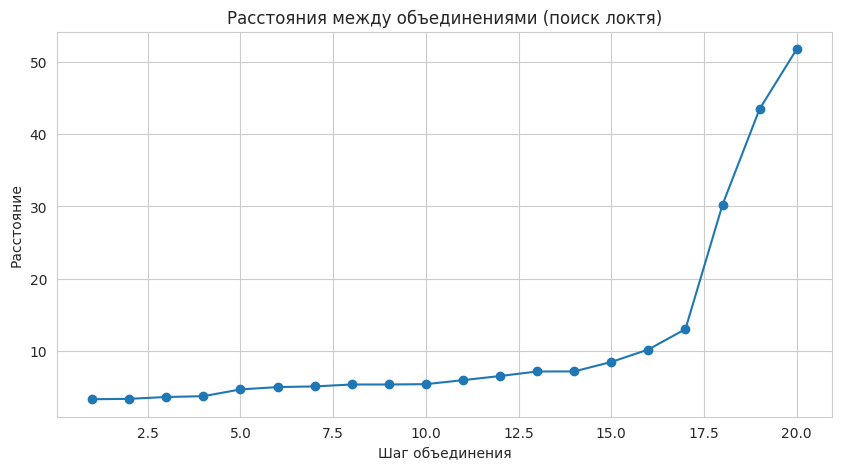

Оценка Силуэта для k=2 до 6:
k=2: 0.455
k=3: 0.614
k=4: 0.727
k=5: 0.698
k=6: 0.729


In [46]:
# 11. Строим график "каменистая осыпь" (расстояния между объединениями)
distances = Z[:, 2] # Берем все расстояния
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), distances[-20:], marker='o') # Показываем последние 20 объединений
plt.title('Расстояния между объединениями (поиск локтя)')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')
plt.grid(True)
plt.show()

# 12. Проверяем качество с помощью коэффициента Силуэта
print("Оценка Силуэта для k=2 до 6:")
for k in range(2, 7):
    labels = fcluster(Z, k, criterion='maxclust')
    score = silhouette_score(df, labels)
    print(f"k={k}: {score:.3f}")

**Объяснение:**
На графике мы видим резкий скачок (локоть) между 13 и 30. Это подтверждает выбор 4 кластеров.
Коэффициент Силуэта тоже высокий (0.727 для k=4). Это значит, что группы получились очень четкими и плотными.
(Для k=5 и 6 оценка еще выше, но такие мелкие группы трудно объяснить с точки зрения маркетинга).

In [47]:
# 13. Применяем кластеризацию (делим на 4 группы)
df['cluster'] = fcluster(Z, 4, criterion='maxclust')

# 14. Смотрим, сколько людей в каждой группе
print("Размеры кластеров:")
print(df['cluster'].value_counts().sort_index())

# 15. Считаем средние значения для каждого кластера
cluster_means = df.groupby('cluster').mean()
display(cluster_means.round(2))

Размеры кластеров:
cluster
1    108
2    110
3     59
4     61
Name: count, dtype: int64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00
4,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75


**Объяснение:**
Мы разделили людей на 4 группы. Группы получились почти одинаковыми по размеру (108, 110, 59, 61 человек).
В таблице средних значений видно, какие вопросы люди из каждой группы оценили высоко.

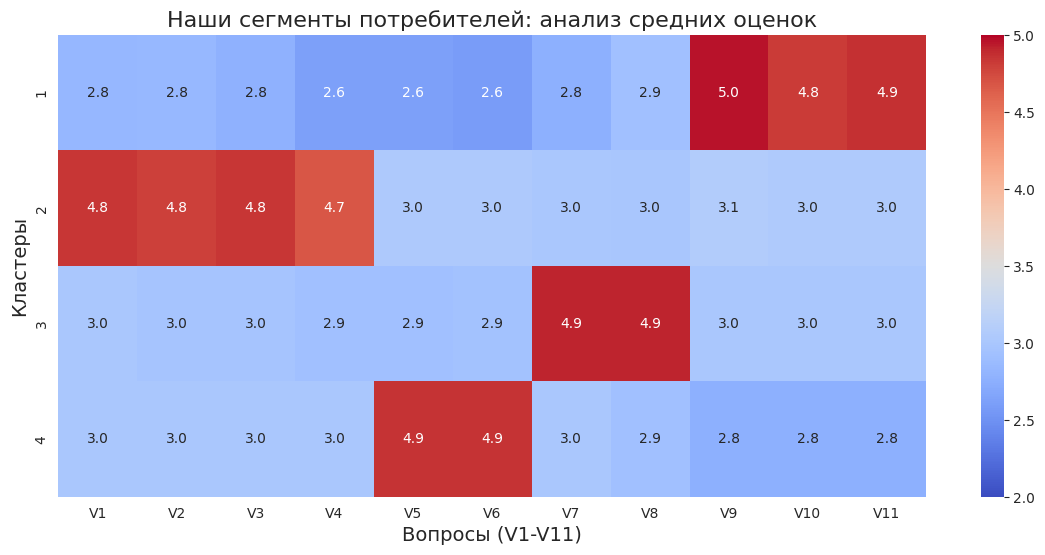

In [42]:
# 16. Рисуем тепловую карту (Heatmap), чтобы увидеть различия
plt.figure(figsize=(14, 6))
sns.heatmap(cluster_means, annot=True, fmt='.1f', cmap='coolwarm', vmin=2, vmax=5)
plt.title('Наши сегменты потребителей: анализ средних оценок', fontsize=16)
plt.xlabel('Вопросы (V1-V11)', fontsize=14)
plt.ylabel('Кластеры', fontsize=14)
plt.show()

**Объяснение (Наша интерпретация):**

На тепловой карте (где красный цвет = высокая оценка) мы видим 4 четких профиля:
1. **Кластер 1:** Красные зоны на V9, V10, V11. Это люди, которые лечатся леденцами от простуды (108 человек).
2. **Кластер 2:** Красные зоны на V1, V2, V3, V4. Это те, для кого важно свежее дыхание и уверенность (110 человек).
3. **Кластер 3:** Красные зоны на V7, V8. Это люди, которым нужно сосредоточиться или отвлечься (59 человек).
4. **Кластер 4:** Красные зоны на V5, V6. Это сладкоежки, которые заменяют леденцами десерт (61 человек).

Мы видим, что рынок разделен: 65% людей покупают леденцы для здоровья или свежести, а 35% - для концентрации или удовольствия.

## Общий вывод

В ходе работы был проведен иерархический кластерный анализ данных о потреблении леденцов (338 респондентов, 11 вопросов).

1. Мы выяснили, что данные не требуют стандартизации, так как все оценки от 2 до 5.
2. Мы выбрали метод Ward, так как он дает самые четкие группы.
3. С помощью дендрограммы, графика расстояний и коэффициента Силуэта мы доказали, что оптимальное число кластеров — **4** (оценка 0.727).
4. Мы выделили четыре сегмента потребителей:
   - Лечебный (108 чел.)
   - Свежесть (110 чел.)
   - Концентрация (59 чел.)
   - Сладкоежки (61 чел.)

**Бизнес-вывод:**
Производители могут делать разную рекламу для этих групп.
Например, для "Лечебного" сегмента - продавать в аптеках, а для "Сладкоежек" - делать низкокалорийные леденцы.